In [36]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Input
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split


In [37]:
df = pd.read_csv("IMDB Dataset.csv")
print(df.head())
print(df.shape)

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
(50000, 2)


In [38]:
x = df["review"]
y = df["sentiment"].map({"positive":1,"negative":0})

x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42
)

In [39]:
train_words = [review.lower().split() for review in x_train]
test_words = [review.lower().split() for review in x_test]
print(train_words[0][:20])

["that's", 'what', 'i', 'kept', 'asking', 'myself', 'during', 'the', 'many', 'fights,', 'screaming', 'matches,', 'swearing', 'and', 'general', 'mayhem', 'that', 'permeate', 'the', '84']


In [40]:
cbow = Word2Vec(
    sentences = train_words,
    vector_size=100,
    window=5,
    min_count=2,
    sg=0,
    epochs=5
)
print("Vocabulary size:",len(cbow.wv))

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Vocabulary size: 133684


In [42]:
x_train_embed = np.array([cbow.wv.get_mean_vector(r) for r in train_words])
x_test_embed = np.array([cbow.wv.get_mean_vector(r) for r in test_words])

print(x_train_embed.shape)
print(x_test_embed.shape)

(40000, 100)
(10000, 100)


In [31]:
model = Sequential([
    Input(shape=(100,)),
    Dense(64,activation="relu"),
    Dense(32,activation="relu"),
    Dense(1,activation="sigmoid")    
])

In [32]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 64)                  │           6,464 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 8,577 (33.50 KB)

 Trainable params: 8,577 (33.50 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
history = model.fit(
    x_train_embed,y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)


Epoch 1/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.7535 - loss: 0.5086 - val_accuracy: 0.8231 - val_loss: 0.4034
Epoch 2/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8192 - loss: 0.4040 - val_accuracy: 0.8295 - val_loss: 0.3953
Epoch 3/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8269 - loss: 0.3918 - val_accuracy: 0.8339 - val_loss: 0.3768
Epoch 4/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8276 - loss: 0.3874 - val_accuracy: 0.8360 - val_loss: 0.3735
Epoch 5/5
500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8290 - loss: 0.3827 - val_accuracy: 0.8376 - val_loss: 0.3725


In [43]:
test_loss,test_accuracy = model.evaluate(x_test_embed,y_test)
print("Test loss:",test_loss)
print("Test Accuracy:",test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5089 - loss: 1.6655    
Test loss: 1.665547251701355
Test Accuracy: 0.508899986743927


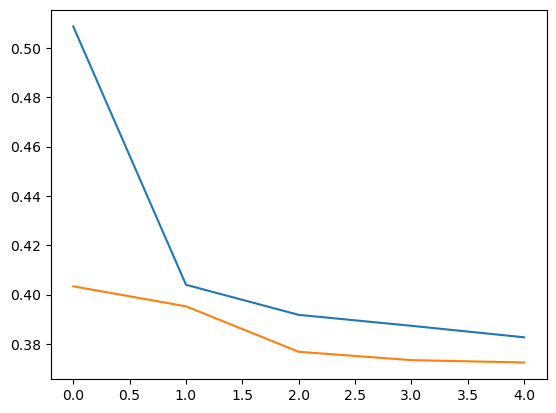

In [44]:
plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.xlabel=("Epoch")
plt.ylabel = ("Loss")
plt.show()

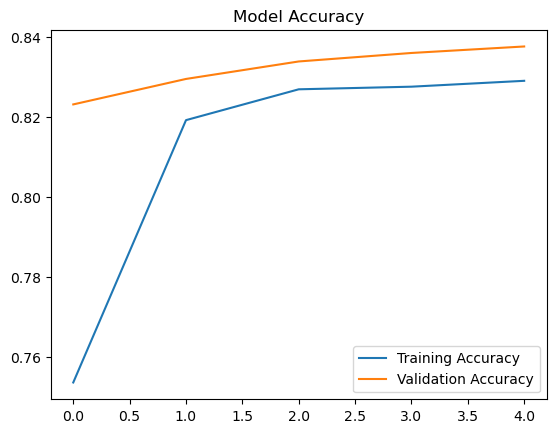

In [46]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel=("Epochs")
plt.ylabel=("Accuracy")
plt.legend()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Input
from gensim.models import Word2Vec
from sklearn.model_selection import train_test_split


df = pd.read_csv("IMDB Dataset.csv")
print(df.head())
print(df.shape)

x = df["review"]
y = df["sentiment"].map({"positive":1,"negative":0})

x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42
)


train_words = [review.lower().split() for review in x_train]
test_words = [review.lower().split() for review in x_test]
print(train_words[0][:20])

cbow = Word2Vec(
    sentences = train_words,
    vector_size=100,
    window=5,
    min_count=2,
    sg=0,
    epochs=5
)
print("Vocabulary size:",len(cbow.wv))


x_train_embed = np.array([cbow.wv.get_mean_vector(r) for r in train_words])
x_test_embed = np.array([cbow.wv.get_mean_vector(r) for r in test_words])

print(x_train_embed.shape)
print(x_test_embed.shape)


model = Sequential([
    Input(shape=(100,)),
    Dense(64,activation="relu"),
    Dense(32,activation="relu"),
    Dense(1,activation="sigmoid")    
])



model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
model.summary()



history = model.fit(
    x_train_embed,y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

test_loss,test_accuracy = model.evaluate(x_test_embed,y_test)
print("Test loss:",test_loss)
print("Test Accuracy:",test_accuracy)


plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.xlabel=("Epoch")
plt.ylabel = ("Loss")
plt.show()

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel=("Epochs")
plt.ylabel=("Accuracy")
plt.legend()
plt.show()

